# Week 6 · Warehouse Space, Throughput, Capacity, Alignment & Performance Scoring
**CadetX — Heavy Supplier, Inventory & Warehouse Analytics · Phase 2 (Core Product, Inventory & Warehouse Analytics)**

Tasks covered this sprint (Task Catalogue, section C):
1. Warehouse Space Utilisation Analysis
2. Warehouse Capacity Analysis
3. Warehouse Throughput Analysis
4. Product–Warehouse Alignment
5. Operational Bottleneck Detection
6. Warehouse Utilisation Benchmarking
7. Warehouse Performance Scoring

**Ground rules** (carried over from Weeks 1-5):
- Shipments and revenue = **Delivered** sales orders, last 12 months to 2024-12-31; revenue ex-GST.
- Receipts and stock history = `stock_ledger.csv` (`implied_signed_quantity`); current stock = `inventory_position.csv`.
- Branch facts (`warehouse_capacity_sqft`, `total_employees`, `monthly_operational_cost`) come from `inventory_position.csv`. `branches.avg_monthly_revenue` was shown in Week 3 to disagree with actual sales, so revenue is always taken from the transactions.
- Recorded stock carries the Week 3 `scale_mismatch_flag`; space results use it as recorded and are read together with that caveat.

In [ ]:
# Mount Google Drive (Colab). Approve the pop-up the first time you run this cell.
from google.colab import drive
drive.mount('/content/drive')

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 9})
BLUE, ORANGE, GREY, RED = "#1f3a93", "#e8743b", "#8a8f98", "#d64545"

# Real Drive locations (corrected copies; the old/ folders hold the uncorrected September files)
BASE = Path("/content/drive/MyDrive/Cadex/HEAVY_SUPPLIERS_WAREHOUSE PROJECT")
SRC = {
    "sales_transactions.csv": BASE / "week-02" / "week-02",
    "inventory_position.csv": BASE / "week-02" / "week-02",
    "purchase_transactions.csv": BASE / "week-02" / "week-02",
    "stock_ledger.csv": BASE / "week-3",
}

# Link the CSVs into one local folder so the loading code below stays unchanged (no big copies)
DATA_DIR = Path("/content/data"); DATA_DIR.mkdir(exist_ok=True)
for name, folder in SRC.items():
    target = folder / name
    if not target.exists():
        raise FileNotFoundError(f"Not found in Drive: {target}  (is Drive mounted? check the folder path)")
    link = DATA_DIR / name
    if link.is_symlink() or link.exists():
        link.unlink()
    link.symlink_to(target)

OUT_DIR = BASE / "week-06" / "outputs"
(OUT_DIR / "charts").mkdir(parents=True, exist_ok=True)

def save(name):
    plt.tight_layout(); plt.savefig(OUT_DIR / "charts" / f"{name}.png", bbox_inches="tight")

## 1. Load data and branch profile

In [2]:
from scipy import stats
inv = pd.read_csv(DATA_DIR / "inventory_position.csv")
sales = pd.read_csv(DATA_DIR / "sales_transactions.csv", usecols=["so_id", "branch_id", "product_id", "quantity", "line_total", "order_status",
                    "order_date", "order_to_delivery_days"], parse_dates=["order_date"], low_memory=False)
led = pd.read_csv(DATA_DIR / "stock_ledger.csv", parse_dates=["movement_date"],
                  usecols=["product_id", "branch_id", "movement_type", "movement_date", "quantity", "implied_signed_quantity"])
pur = pd.read_csv(DATA_DIR / "purchase_transactions.csv", usecols=["branch_id", "po_status", "po_lead_variance_days"], low_memory=False)

d = sales[sales.order_status == "Delivered"]
END = d.order_date.max(); L12_START = END - pd.Timedelta(days=365)
L12 = d[d.order_date > L12_START]
led12 = led[(led.movement_date > L12_START) & (led.movement_date <= END)]

br = (inv.drop_duplicates("branch_id").set_index("branch_id")[["branch_name", "region", "warehouse_type", "service_center_available",
      "total_employees", "monthly_operational_cost", "warehouse_capacity_sqft", "market_demand_index"]])
br["floor_m2"] = br.warehouse_capacity_sqft * 0.092903
print(f"Window: {L12_START.date()} to {END.date()}")
br

Window: 2024-01-01 to 2024-12-31

,branch_name,region,warehouse_type,service_center_available,total_employees,monthly_operational_cost,warehouse_capacity_sqft,market_demand_index,floor_m2
branch_id,,,,,,,,,
DEL001,Delhi Central,North,Central,Yes,92,3189000,45230,9,4202.00269
PUN001,Pune Distribution,West,Regional,Yes,74,2654000,38750,8,3599.99125
CHN001,Chennai South Hub,South,Regional,Yes,81,2739000,41890,8,3891.70667
HYD001,Hyderabad Logistics,South,Branch,No,57,1887000,36210,7,3364.01763
KOL001,Kolkata East Depot,East,Branch,No,49,1743000,29880,6,2775.94164
AHM001,Ahmedabad West Hub,West,Service Hub,Yes,63,2018000,34120,7,3169.85036


## 2. Warehouse Space Utilisation & Capacity
Every product has a unit size (`dimensions_cm`) and weight, so recorded stock can be converted into **cubic metres** and compared with each branch's floor area.
- **Implied stacking height** = stock volume ÷ floor area. It is the height the goods would have to be piled to fit, with no aisles. This needs no assumption about the building.
- **Utilisation** compares stock volume with usable volume = floor area × `STACK_HEIGHT_M`. The 6 m default is an **assumption** (typical racked warehouse), not a data field; change it to see the effect.

In [3]:
STACK_HEIGHT_M = 6.0   # assumption: usable stacking/racking height

dims = inv.dimensions_cm.str.split("x", expand=True).astype(float)
inv["unit_m3"] = dims.prod(axis=1) / 1e6
inv["stock_m3"] = inv.current_stock * inv.unit_m3
inv["max_m3"] = inv.max_stock * inv.unit_m3
inv["stock_tonnes"] = inv.current_stock * inv.weight_kg / 1000

sp = inv.groupby("branch_id").agg(stock_m3=("stock_m3", "sum"), max_m3=("max_m3", "sum"), stock_tonnes=("stock_tonnes", "sum"))
sp = br[["branch_name", "warehouse_capacity_sqft", "floor_m2"]].join(sp)
sp["usable_m3"] = sp.floor_m2 * STACK_HEIGHT_M
sp["implied_height_m"] = sp.stock_m3 / sp.floor_m2
sp["utilisation_recorded_pct"] = sp.stock_m3 / sp.usable_m3 * 100
sp["utilisation_at_max_stock_pct"] = sp.max_m3 / sp.usable_m3 * 100
print(sp[["branch_name", "warehouse_capacity_sqft", "stock_m3", "implied_height_m", "utilisation_recorded_pct", "utilisation_at_max_stock_pct"]].round(1).to_string(index=False))
print(f"\nRecorded stock would need stacking {sp.implied_height_m.min():.0f} to {sp.implied_height_m.max():.0f} m high over the whole floor; at the {STACK_HEIGHT_M:.0f} m assumption that is "
      f"{sp.utilisation_recorded_pct.min():,.0f}% to {sp.utilisation_recorded_pct.max():,.0f}% of usable space.")
print(f"Stock held at policy max stock would fill only {sp.utilisation_at_max_stock_pct.min():.1f}% to {sp.utilisation_at_max_stock_pct.max():.1f}% of usable space.")

        branch_name  warehouse_capacity_sqft  stock_m3  implied_height_m  utilisation_recorded_pct  utilisation_at_max_stock_pct
      Delhi Central                    45230  217247.8              51.7                     861.7                           2.9
  Pune Distribution                    38750  219777.8              61.0                    1017.5                           2.0
  Chennai South Hub                    41890  225576.0              58.0                     966.1                           2.9
Hyderabad Logistics                    36210  221698.6              65.9                    1098.4                           3.0
 Kolkata East Depot                    29880  206961.2              74.6                    1242.6                           5.3
 Ahmedabad West Hub                    34120  212221.5              66.9                    1115.8                           2.4

Recorded stock would need stacking 52 to 75 m high over the whole floor; at the 6 m assumption t

In [4]:
inb = led[led.movement_type == "IN"].merge(inv[["product_id", "branch_id", "unit_m3"]], on=["product_id", "branch_id"])
inb["m3"] = inb.quantity * inb.unit_m3
yr = inb[inb.movement_date.dt.year == 2024].groupby("branch_id").m3.sum()
sp["inbound_2024_m3"] = yr
sp["inbound_2024_pct_of_usable"] = sp.inbound_2024_m3 / sp.usable_m3 * 100
cat_m3 = inv.groupby("category").stock_m3.sum().sort_values(ascending=False)
print("2024 inbound volume as % of each branch's usable space:", sp.inbound_2024_pct_of_usable.round(0).to_dict())
print("Share of stock volume by category:", (cat_m3 / cat_m3.sum() * 100).round(1).head(4).to_dict())
print(f"Total recorded stock weight: {inv.stock_tonnes.sum():,.0f} tonnes")

2024 inbound volume as % of each branch's usable space: {'DEL001': 147.0, 'PUN001': 177.0, 'CHN001': 161.0, 'HYD001': 175.0, 'KOL001': 217.0, 'AHM001': 184.0}
Share of stock volume by category: {'Engine': 37.2, 'Transmission': 31.8, 'Undercarriage': 17.8, 'Hydraulic': 7.8}
Total recorded stock weight: 713,065 tonnes

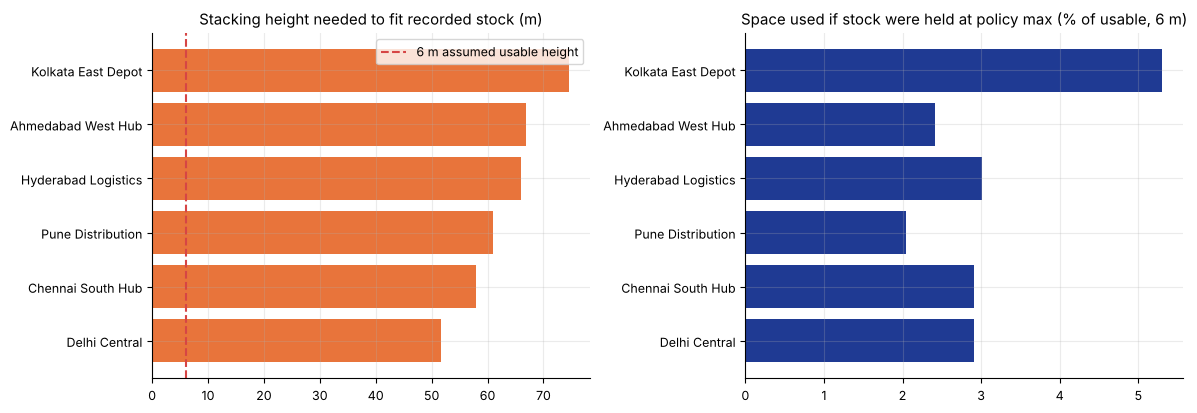

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
s = sp.sort_values("implied_height_m")
ax[0].barh(s.branch_name, s.implied_height_m, color=ORANGE); ax[0].axvline(STACK_HEIGHT_M, c=RED, ls="--", label=f"{STACK_HEIGHT_M:.0f} m assumed usable height")
ax[0].set_title("Stacking height needed to fit recorded stock (m)"); ax[0].legend()
ax[1].barh(s.branch_name, s.utilisation_at_max_stock_pct, color=BLUE); ax[1].set_title(f"Space used if stock were held at policy max (% of usable, {STACK_HEIGHT_M:.0f} m)")
save("01_space_utilisation")

## 3. Warehouse Throughput Analysis
Throughput over the last 12 months: units **shipped** (Delivered sales) and units **received** (purchase receipts in the ledger), per branch, per employee and per 1,000 sq ft, and the operating cost per unit handled. Operating cost is `monthly_operational_cost × 12`.

In [6]:
ship = L12.groupby("branch_id").agg(units_shipped=("quantity", "sum"), order_lines=("so_id", "size"), revenue=("line_total", "sum"))
recv = led12[led12.movement_type == "IN"].groupby("branch_id").quantity.sum().rename("units_received")
tp = br[["branch_name", "total_employees", "warehouse_capacity_sqft", "monthly_operational_cost"]].join(ship).join(recv)
tp["annual_cost"] = tp.monthly_operational_cost * 12
tp["units_handled"] = tp.units_shipped + tp.units_received
tp["shipped_per_employee"] = tp.units_shipped / tp.total_employees
tp["handled_per_employee"] = tp.units_handled / tp.total_employees
tp["shipped_per_1000sqft"] = tp.units_shipped / tp.warehouse_capacity_sqft * 1000
tp["cost_per_unit_shipped"] = tp.annual_cost / tp.units_shipped
tp["cost_per_unit_handled"] = tp.annual_cost / tp.units_handled
tp["revenue_per_sqft"] = tp.revenue / tp.warehouse_capacity_sqft
tp["revenue_per_employee_cr"] = tp.revenue / tp.total_employees / 1e7
tp["cost_pct_of_revenue"] = tp.annual_cost / tp.revenue * 100
m = d.groupby(["branch_id", d.order_date.dt.to_period("M")]).quantity.sum().unstack(0)
tp["peak_to_avg_month"] = (m.max() / m.mean()).values
show = ["branch_name", "units_shipped", "units_received", "shipped_per_employee", "shipped_per_1000sqft", "cost_per_unit_shipped",
        "cost_per_unit_handled", "revenue_per_sqft", "cost_pct_of_revenue", "peak_to_avg_month"]
print(tp[show].round(1).to_string(index=False))
print(f"\nReceipts are {tp.units_received.sum()/tp.units_shipped.sum():.1f}x shipments, so inbound handling is most of the workload.")
rec_ratio = (inv.drop_duplicates("branch_id").set_index("branch_id").avg_monthly_revenue * 12) / tp.revenue
print(f"Branch-table revenue (avg_monthly_revenue x 12) is only {rec_ratio.min()*100:.0f}% to {rec_ratio.max()*100:.0f}% of actual shipped revenue, so it is not used.")

        branch_name  units_shipped  units_received  shipped_per_employee  shipped_per_1000sqft  cost_per_unit_shipped  cost_per_unit_handled  revenue_per_sqft  cost_pct_of_revenue  peak_to_avg_month
      Delhi Central          31797          571289                 345.6                 703.0                 1203.5                   63.5           12536.8                  6.7                1.5
  Pune Distribution          30703          549352                 414.9                 792.3                 1037.3                   54.9           14286.2                  5.8                1.7
  Chennai South Hub          40132          582066                 495.5                 958.0                  819.0                   52.8           17570.1                  4.5                1.4
Hyderabad Logistics          27917          534712                 489.8                 771.0                  811.1                   40.2           14380.7                  4.3                1.4
 Kolk

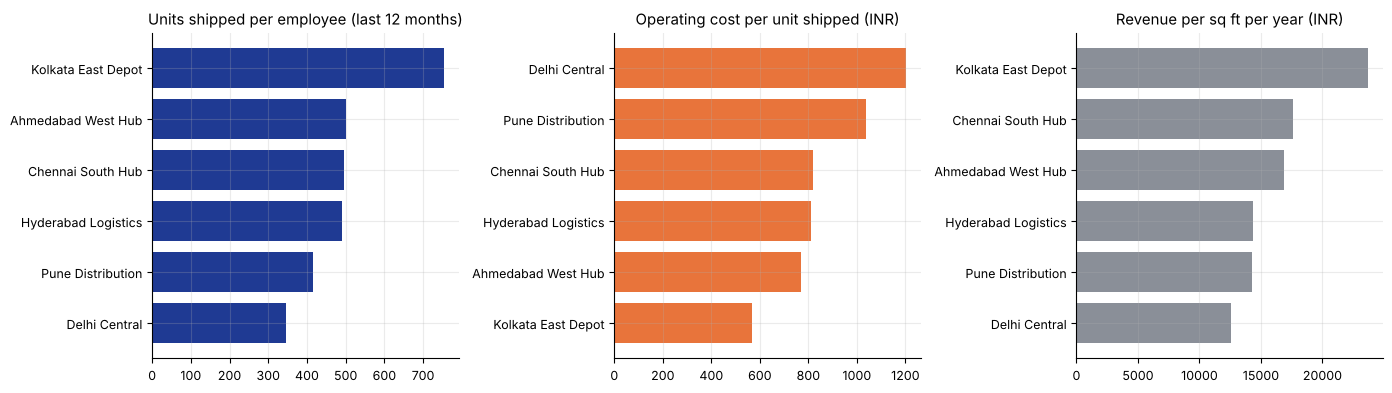

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
t = tp.sort_values("shipped_per_employee")
ax[0].barh(t.branch_name, t.shipped_per_employee, color=BLUE); ax[0].set_title("Units shipped per employee (last 12 months)")
t = tp.sort_values("cost_per_unit_shipped")
ax[1].barh(t.branch_name, t.cost_per_unit_shipped, color=ORANGE); ax[1].set_title("Operating cost per unit shipped (INR)")
t = tp.sort_values("revenue_per_sqft")
ax[2].barh(t.branch_name, t.revenue_per_sqft, color=GREY); ax[2].set_title("Revenue per sq ft per year (INR)")
save("02_throughput")

## 4. Product–Warehouse Alignment
Does each branch hold the products its customers actually buy, and is space and staffing spread in line with demand?
- **Alignment index** = 1 − half the sum of |demand share − stock share| across the 30 products (1.0 = stock mix mirrors demand exactly).
- Branch share of national demand, capacity, staff and stock side by side.

In [8]:
dem = L12.groupby(["branch_id", "product_id"]).quantity.sum().unstack(fill_value=0)
stk = inv.pivot(index="branch_id", columns="product_id", values="current_stock")
mx = inv.pivot(index="branch_id", columns="product_id", values="max_stock")
d_sh, s_sh, m_sh = (x.div(x.sum(axis=1), axis=0) for x in (dem, stk, mx))
al = pd.DataFrame({"alignment_stock_vs_demand": 1 - 0.5 * (d_sh - s_sh).abs().sum(axis=1),
                   "alignment_maxstock_vs_demand": 1 - 0.5 * (d_sh - m_sh).abs().sum(axis=1)})
shares = pd.DataFrame({"demand_share_pct": tp.units_shipped / tp.units_shipped.sum() * 100,
                       "capacity_share_pct": br.warehouse_capacity_sqft / br.warehouse_capacity_sqft.sum() * 100,
                       "staff_share_pct": br.total_employees / br.total_employees.sum() * 100,
                       "stock_share_pct": inv.groupby("branch_id").current_stock.sum() / inv.current_stock.sum() * 100})
al = br[["branch_name"]].join(al).join(shares)
al["demand_per_1000sqft"] = tp.shipped_per_1000sqft
print(al.round(3).to_string(index=False))
print(f"\nCapacity share vs demand share, largest gaps (pct points): {(al.capacity_share_pct - al.demand_share_pct).round(1).to_dict()}")

        branch_name  alignment_stock_vs_demand  alignment_maxstock_vs_demand  demand_share_pct  capacity_share_pct  staff_share_pct  stock_share_pct  demand_per_1000sqft
      Delhi Central                      0.945                         0.834            15.976              20.006           22.115           17.037              703.007
  Pune Distribution                      0.949                         0.846            15.426              17.140           17.788           16.869              792.335
  Chennai South Hub                      0.955                         0.838            20.164              18.529           19.471           16.755              958.033
Hyderabad Logistics                      0.946                         0.850            14.027              16.016           13.702           16.812              770.975
 Kolkata East Depot                      0.951                         0.857            18.568              13.217           11.779           16.183  

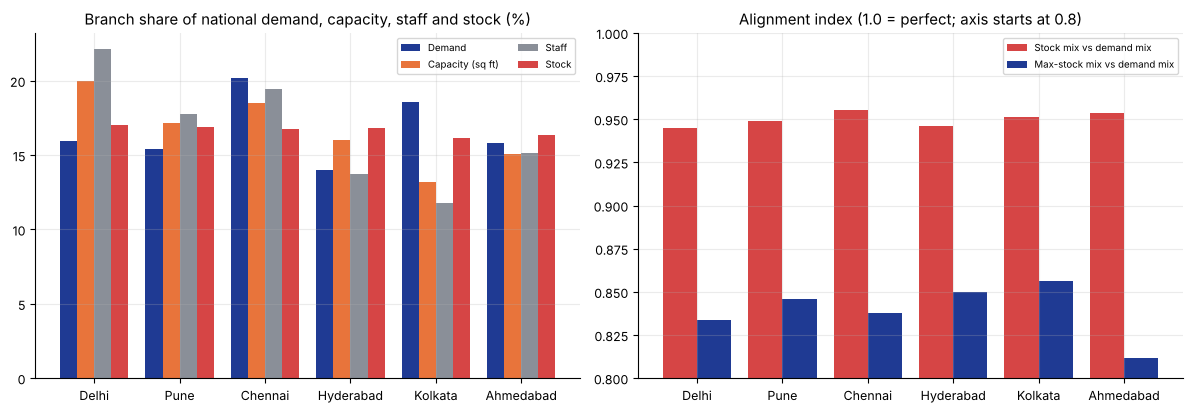

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(len(al)); w = .2
for i, (c, col, lab) in enumerate([("demand_share_pct", BLUE, "Demand"), ("capacity_share_pct", ORANGE, "Capacity (sq ft)"),
                                   ("staff_share_pct", GREY, "Staff"), ("stock_share_pct", RED, "Stock")]):
    ax[0].bar(x + (i - 1.5) * w, al[c], w, color=col, label=lab)
ax[0].set_xticks(x); ax[0].set_xticklabels([n.split(" ")[0] for n in al.branch_name]); ax[0].set_title("Branch share of national demand, capacity, staff and stock (%)"); ax[0].legend(fontsize=7, ncol=2)
ax[1].bar(x - .2, al.alignment_stock_vs_demand, .4, color=RED, label="Stock mix vs demand mix"); ax[1].bar(x + .2, al.alignment_maxstock_vs_demand, .4, color=BLUE, label="Max-stock mix vs demand mix")
ax[1].set_xticks(x); ax[1].set_xticklabels([n.split(" ")[0] for n in al.branch_name]); ax[1].set_ylim(.8, 1); ax[1].set_title("Alignment index (1.0 = perfect; axis starts at 0.8)"); ax[1].legend(fontsize=7)
save("03_alignment")

## 5. Operational Bottleneck Detection
Each candidate bottleneck is compared across branches. With 18,000-27,000 orders per branch, even tiny differences test as "statistically significant", so two things are checked: a significance test (p < 0.05) **and** the size of the gap (highest branch at least `PRACTICAL_GAP_PCT` = 25% above the lowest). A measure is flagged as a bottleneck only if both hold.
- Order cancellation rate (chi-square test)
- Order-to-delivery days on delivered orders (Kruskal-Wallis test)
- Inbound lateness: purchase receipts later than planned (chi-square) and mean lateness (Kruskal-Wallis)
- Peak-month load against the average month

In [10]:
s = sales.copy(); s["cancelled"] = (s.order_status == "Cancelled").astype(int)
can = s.groupby("branch_id").agg(lines=("so_id", "size"), cancelled=("cancelled", "sum")); can["cancel_rate_pct"] = can.cancelled / can.lines * 100
p_can = stats.chi2_contingency(np.c_[can.cancelled, can.lines - can.cancelled])[1]

dd = d.groupby("branch_id").order_to_delivery_days
dl = dd.agg(["mean", lambda x: x.quantile(.9)]); dl.columns = ["mean_delivery_days", "p90_delivery_days"]
p_del = stats.kruskal(*[g.values for _, g in dd])[1]

pr = pur[pur.po_status == "Received"].copy(); pr["late"] = (pr.po_lead_variance_days > 0).astype(int)
inb_t = pr.groupby("branch_id").agg(receipts=("late", "size"), late=("late", "sum"), mean_late_days=("po_lead_variance_days", "mean")); inb_t["late_pct"] = inb_t.late / inb_t.receipts * 100
p_late = stats.chi2_contingency(np.c_[inb_t.late, inb_t.receipts - inb_t.late])[1]
p_latedays = stats.kruskal(*[g.po_lead_variance_days.values for _, g in pr.groupby("branch_id")])[1]

checks = pd.DataFrame([
    ["Order cancellation rate", can.cancel_rate_pct.min(), can.cancel_rate_pct.max(), p_can],
    ["Order-to-delivery days (mean)", dl.mean_delivery_days.min(), dl.mean_delivery_days.max(), p_del],
    ["Inbound receipts late (%)", inb_t.late_pct.min(), inb_t.late_pct.max(), p_late],
    ["Inbound lateness (mean days)", inb_t.mean_late_days.min(), inb_t.mean_late_days.max(), p_latedays]],
    columns=["measure", "lowest_branch", "highest_branch", "p_value"])
PRACTICAL_GAP_PCT = 25
checks["gap_pct"] = (checks.highest_branch / checks.lowest_branch - 1) * 100
checks["statistically_significant"] = checks.p_value < 0.05
checks["practically_meaningful"] = checks.gap_pct >= PRACTICAL_GAP_PCT
checks["bottleneck_flag"] = checks.statistically_significant & checks.practically_meaningful
print(checks.round(4).to_string(index=False))
print(f"\nBottlenecks flagged: {int(checks.bottleneck_flag.sum())}. Differences are detectable but small (largest gap {checks.gap_pct.max():.0f}%).")
print(); print(can.round(2).join(br.branch_name)[["branch_name", "cancel_rate_pct"]].to_string())

                      measure  lowest_branch  highest_branch  p_value  gap_pct  statistically_significant  practically_meaningful  bottleneck_flag
      Order cancellation rate         9.3116         10.5643   0.0000  13.4527                       True                   False            False
Order-to-delivery days (mean)         7.9797          8.1245   0.0007   1.8139                       True                   False            False
    Inbound receipts late (%)        14.2703         15.7116   0.0002  10.1000                       True                   False            False
 Inbound lateness (mean days)         0.4592          0.5364   0.0260  16.8084                       True                   False            False

Bottlenecks flagged: 0. Differences are detectable but small (largest gap 17%).

                   branch_name  cancel_rate_pct
branch_id                                      
AHM001      Ahmedabad West Hub             9.35
CHN001       Chennai South Hub         

In [11]:
print("Order-to-delivery days: overall mean %.1f, p90 %.0f, max %d; delivered in more than 10 days: %.1f%%" %
      (d.order_to_delivery_days.mean(), d.order_to_delivery_days.quantile(.9), d.order_to_delivery_days.max(), (d.order_to_delivery_days > 10).mean() * 100))
print("Peak month vs average month, by branch:", tp.peak_to_avg_month.round(2).to_dict())
tp_z = (tp.shipped_per_employee - tp.shipped_per_employee.mean()) / tp.shipped_per_employee.std()
print("Shipped per employee, spread across branches:", f"{tp.shipped_per_employee.min():.0f} to {tp.shipped_per_employee.max():.0f}  (largest gap {tp.shipped_per_employee.max()/tp.shipped_per_employee.min():.1f}x)")

Order-to-delivery days: overall mean 8.1, p90 14, max 15; delivered in more than 10 days: 33.8%
Peak month vs average month, by branch: {'DEL001': 1.48, 'PUN001': 1.68, 'CHN001': 1.42, 'HYD001': 1.39, 'KOL001': 1.45, 'AHM001': 1.48}
Shipped per employee, spread across branches: 346 to 754  (largest gap 2.2x)

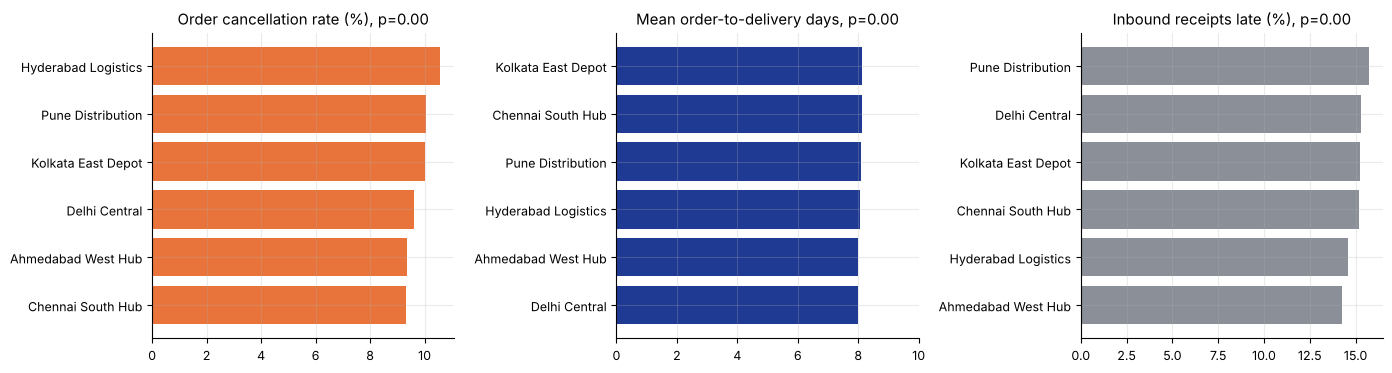

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
c = can.join(br.branch_name).sort_values("cancel_rate_pct"); ax[0].barh(c.branch_name, c.cancel_rate_pct, color=ORANGE); ax[0].set_title(f"Order cancellation rate (%), p={p_can:.2f}")
x = dl.join(br.branch_name).sort_values("mean_delivery_days"); ax[1].barh(x.branch_name, x.mean_delivery_days, color=BLUE); ax[1].set_title(f"Mean order-to-delivery days, p={p_del:.2f}"); ax[1].set_xlim(0, 10)
y = inb_t.join(br.branch_name).sort_values("late_pct"); ax[2].barh(y.branch_name, y.late_pct, color=GREY); ax[2].set_title(f"Inbound receipts late (%), p={p_late:.2f}")
save("04_bottlenecks")

## 6. Warehouse Utilisation Benchmarking and Performance Scoring
Candidate KPIs are scaled 0-100 across the six branches (best branch = 100, worst = 0; for "lower is better" KPIs the scale is reversed) and averaged with equal weights into a score.
Scaling stretches any gap to the full 0-100 range, so a KPI where branches differ by only a few percent would add noise to the score. A KPI is therefore **scored only if its best and worst branch differ by at least 25%**; the others are shown as "no practical difference" and left out.
Because six branches and equal weights are a simplification, the ranking is also re-run under 5,000 random weightings to show how stable it is. Note that shipped per employee, revenue per sq ft and cost per unit shipped share the same numerator (units shipped), so the score leans on shipping volume relative to branch size.

In [13]:
kp = pd.DataFrame({
    "shipped_per_employee": tp.shipped_per_employee,
    "revenue_per_sqft": tp.revenue_per_sqft,
    "cost_per_unit_shipped": tp.cost_per_unit_shipped,
    "years_of_supply": inv.groupby("branch_id").current_stock.sum() / tp.units_shipped,
    "stock_to_max": inv.groupby("branch_id").current_stock.sum() / inv.groupby("branch_id").max_stock.sum(),
    "cancel_rate_pct": can.cancel_rate_pct,
    "mean_delivery_days": dl.mean_delivery_days,
    "inbound_late_pct": inb_t.late_pct})
higher_better = {"shipped_per_employee": True, "revenue_per_sqft": True, "cost_per_unit_shipped": False, "years_of_supply": False,
                 "stock_to_max": False, "cancel_rate_pct": False, "mean_delivery_days": False, "inbound_late_pct": False}
spread = (kp.max() / kp.min() - 1) * 100
scored = [c for c in kp if spread[c] >= 25]
print("Best-vs-worst branch gap by KPI (%):", spread.round(0).to_dict())
print("Scored:", scored); print("Left out (no practical difference):", [c for c in kp if c not in scored])
higher_better = {c: higher_better[c] for c in scored}
norm = kp[scored].copy()
for c, hb in higher_better.items():
    z = (kp[c] - kp[c].min()) / (kp[c].max() - kp[c].min()) * 100
    norm[c] = z if hb else 100 - z
norm["score"] = norm.mean(axis=1)
score = br[["branch_name"]].join(norm).sort_values("score", ascending=False)
score["rank"] = range(1, len(score) + 1)
print(score.round(1).to_string(index=False))

rng = np.random.default_rng(42); W = rng.dirichlet(np.ones(len(higher_better)), 5000)
sc = norm[list(higher_better)].values @ W.T                       # branches x draws
ranks = (-sc).argsort(axis=0).argsort(axis=0) + 1
stab = pd.DataFrame({"share_ranked_1st_pct": (ranks == 1).mean(axis=1) * 100, "share_in_top3_pct": (ranks <= 3).mean(axis=1) * 100,
                     "average_rank": ranks.mean(axis=1)}, index=norm.index)
stab = br[["branch_name"]].join(stab).sort_values("average_rank")
print(); print(stab.round(1).to_string(index=False))

Best-vs-worst branch gap by KPI (%): {'shipped_per_employee': 118.0, 'revenue_per_sqft': 89.0, 'cost_per_unit_shipped': 113.0, 'years_of_supply': 44.0, 'stock_to_max': 32.0, 'cancel_rate_pct': 13.0, 'mean_delivery_days': 2.0, 'inbound_late_pct': 10.0}
Scored: ['shipped_per_employee', 'revenue_per_sqft', 'cost_per_unit_shipped', 'years_of_supply', 'stock_to_max']
Left out (no practical difference): ['cancel_rate_pct', 'mean_delivery_days', 'inbound_late_pct']
        branch_name  shipped_per_employee  revenue_per_sqft  cost_per_unit_shipped  years_of_supply  stock_to_max  score  rank
 Kolkata East Depot                 100.0             100.0                  100.0             89.0         100.0   97.8     1
  Chennai South Hub                  36.7              44.9                   60.3            100.0          48.7   58.1     2
 Ahmedabad West Hub                  37.9              38.6                   68.3             45.3          59.4   49.9     3
Hyderabad Logistics          

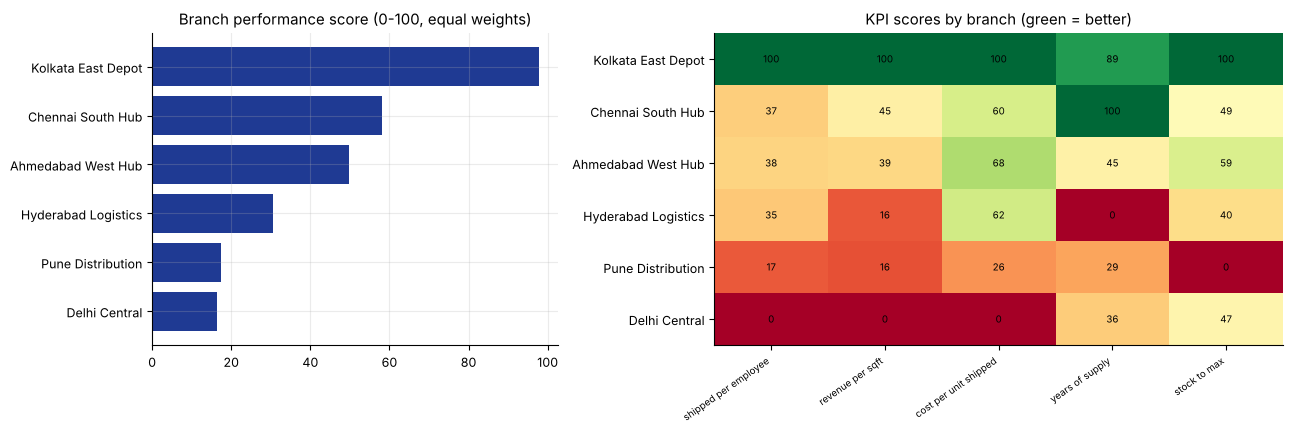

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.4]})
s = score.sort_values("score"); ax[0].barh(s.branch_name, s.score, color=BLUE); ax[0].set_title("Branch performance score (0-100, equal weights)")
cols = list(higher_better); hm = score[cols].values
im = ax[1].imshow(hm, cmap="RdYlGn", vmin=0, vmax=100, aspect="auto")
ax[1].set_yticks(range(len(score))); ax[1].set_yticklabels(score.branch_name); ax[1].set_xticks(range(len(cols)))
ax[1].set_xticklabels([c.replace("_", " ") for c in cols], rotation=35, ha="right", fontsize=7); ax[1].grid(False)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]): ax[1].text(j, i, f"{hm[i, j]:.0f}", ha="center", va="center", fontsize=7)
ax[1].set_title("KPI scores by branch (green = better)")
save("05_scorecard")

## 7. Export results

In [15]:
sp.drop(columns=["floor_m2"]).round(2).reset_index().to_csv(OUT_DIR / "space_utilisation.csv", index=False)
tp.round(3).reset_index().to_csv(OUT_DIR / "branch_throughput_kpis.csv", index=False)
al.round(4).reset_index().to_csv(OUT_DIR / "product_warehouse_alignment.csv", index=False)
checks.round(4).to_csv(OUT_DIR / "bottleneck_checks.csv", index=False)
score.round(2).reset_index().to_csv(OUT_DIR / "branch_scorecard.csv", index=False)
stab.round(1).reset_index().to_csv(OUT_DIR / "score_rank_stability.csv", index=False)
print(sorted(p.name for p in OUT_DIR.glob("*.csv")), len(list((OUT_DIR / "charts").glob("*.png"))), "charts")

['bottleneck_checks.csv', 'branch_scorecard.csv', 'branch_throughput_kpis.csv', 'product_warehouse_alignment.csv', 'score_rank_stability.csv', 'space_utilisation.csv'] 5 charts